# Build Meisner Scenario — All Input Files

Generates **all simulation input files** for the Meisner et al. (2025) battlefield
scenario from a single parametric configuration cell.

**Topology (configurable in Cell 1)**
- Variable number of brigades, each with a configurable number of battalions
- Variable Role-1 MTFs per brigade (placed evenly across brigade width)
- Variable Role-2 MTFs per brigade (placed evenly across brigade width)
- 1 CCP per battalion, 1 AXP per brigade

**Default: 3 brigades × 3 battalions, 3 R1/brigade, 3 R2/brigade (Meisner et al. 2025)**

**Output files** (written to `data/single_run/input/`):

| Sub-path | Description |
|---|---|
| `components/distances/distance_matrix_{SUFFIX}.xlsx` | Euclidean distance matrix |
| `components/distances/coordinates_{SUFFIX}.xlsx` | Coordinate reference |
| `components/facilities/facilities_{SUFFIX}.xlsx` | CCP / R1 / R2 facilities |
| `components/units/units_{SUFFIX}.xlsx` | DCR, PEC, DCS service units |
| `components/AXPs/axp_{SUFFIX}.xlsx` | Ambulance exchange points |
| `components/ambulances/amb_{SUFFIX}.xlsx` | Ambulance fleet |
| `components/c2/c2_{SUFFIX}.xlsx` | C2 nodes |
| `policy_matrixes/…/facility_eligibility_{SUFFIX}_strict/loose.xlsx` | Facility routing policy |
| `policy_matrixes/…/ambulance_eligibility_{SUFFIX}_strict/loose.xlsx` | Ambulance routing policy |


In [45]:
import pathlib, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

## Cell 1 — Configuration

Edit the parameters below to change geometry, order of battle, and logistics.
All downstream cells derive from these values automatically.

In [ ]:
# ── Facility counts ────────────────────────────────────────────
N_CCP = 3
N_R1  = 1
N_AXP =  1
N_R2  = 1

# ── Geometry (km) ────────────────────────────────────────────
FRONTAGE_KM = 30.0
Y_CCP  =  4.0
Y_R1   =  7.0
Y_AXP  = 12.0
Y_R2   = 20.0

# ── Unit service-time parameters ──────────────────────────────────────────
DCS_CAPACITY                    = 2
DCS_MILD_MEAN,   DCS_MILD_STD   = 93.9,  41.3
DCS_SEVERE_MEAN, DCS_SEVERE_STD = 180.0, 83.0
DCR_CAPACITY, DCR_MIN, DCR_MAX  = 2, 27, 28
PEC_CAPACITY, PEC_MIN, PEC_MAX  = 2, 27, 28

# ── Fleet CCP→R1 parameters ──────────────────────────────────────────
CCP_AMBS_PER_R1      = 1    # ambulances per R1, stationed at the R1
AMB_CCP_R1_T1T2_CAPACITY = 2
AMB_CCP_R1_T3_CAPACITY   = 3
AMB_CCP_R1_SPEED_KMH     = 30

# ── Fleet R1→R2 parameters ─────────────────────────────────────────
R1R2_AMBS_PER_AXP    = 4    # ambulances per AXP, stationed at the AXP
AMB_R1_R2_T1T2_CAPACITY  = 2
AMB_R1_R2_T3_CAPACITY    = 3
AMB_R1_R2_SPEED_KMH      = 30

# ── Output & naming ────────────────────────────────────────────
# Path is relative to this notebook (data_notebooks/) → one level up to repo root.
OUT_BASE = pathlib.Path("../data/single_run/input")
SUFFIX   = "elia_testing"

# ── Casualty config (source of truth for rates, force structure, schedule) ─────
# Points to:  data/single_run/input/casualty_generation_settings/sampling_settings/config_{SUFFIX}.yaml
# Edit that file to change PAR, bcas_rate, dnbi_rate, n_days, waves_per_day, wave_duration_min.
CASUALTY_CONFIG = f"config_{SUFFIX}"

# ── Scenario parameters ────────────────────────────────────────────
SCENARIO_NAME        = f"scenario_{SUFFIX}"
SCENARIO_DESCRIPTION = "Auto-generated scenario"
SEED                 = 42
SIM_TILL_MIN         = 60*24*3   # simulation end time in minutes
DISPATCH_POLICY      = "greedy"   # "greedy" or "ilp"
DATA_COLLECTOR_INTERVAL = 10.0   # minutes between DataCollector snapshots


## Cell 2 — Build facility coordinates

In [47]:
nodes = []

# x-coordinates for each tier (independent counts)
ccp_xs = {f"ccp_{i}": (i - 0.5) * FRONTAGE_KM / N_CCP for i in range(1, N_CCP + 1)}
r1_xs  = {f"r1_{i}":  (i - 0.5) * FRONTAGE_KM / N_R1  for i in range(1, N_R1  + 1)}
axp_xs = {f"axp_{i}": (i - 0.5) * FRONTAGE_KM / N_AXP for i in range(1, N_AXP + 1)}

# CCPs
for fid, x in ccp_xs.items():
    nodes.append({"facility_id": fid, "facility_type": "CCP",   "x": x, "y": Y_CCP})

# R1s
for fid, x in r1_xs.items():
    nodes.append({"facility_id": fid, "facility_type": "Role1", "x": x, "y": Y_R1})

# AXPs
for fid, x in axp_xs.items():
    nodes.append({"facility_id": fid, "facility_type": "AXP",   "x": x, "y": Y_AXP})

# R2s
for i in range(1, N_R2 + 1):
    x = (i - 0.5) * FRONTAGE_KM / N_R2
    nodes.append({"facility_id": f"r2_{i}", "facility_type": "Role2", "x": x, "y": Y_R2})

fac_df = pd.DataFrame(nodes)

# Assign each CCP to its nearest R1
ccp_to_r1    = {ccp: min(r1_xs, key=lambda r, x=x: abs(r1_xs[r] - x))
                for ccp, x in ccp_xs.items()}
ccp_r1_pairs = list(ccp_to_r1.items())   # [(ccp_id, r1_id)]

# Assign each R1 / R2 to its nearest AXP (used for strict eligibility and AXP routing)
r1_to_axp = {r1: min(axp_xs, key=lambda a, x=x: abs(axp_xs[a] - x))
             for r1, x in r1_xs.items()}
r2_to_axp = {f"r2_{i}": min(axp_xs, key=lambda a: abs(axp_xs[a] - (i - 0.5) * FRONTAGE_KM / N_R2))
             for i in range(1, N_R2 + 1)}
axp_to_r1s = {}
for r1, axp in r1_to_axp.items():
    axp_to_r1s.setdefault(axp, []).append(r1)

print(f"Map nodes: {len(fac_df)}  (CCP={N_CCP}, R1={N_R1}, AXP={N_AXP}, R2={N_R2})")
print(f"CCP→R1: {ccp_to_r1}")
print(f"R1→AXP: {r1_to_axp}")


Map nodes: 6  (CCP=3, R1=1, AXP=1, R2=1)
CCP→R1: {'ccp_1': 'r1_1', 'ccp_2': 'r1_1', 'ccp_3': 'r1_1'}
R1→AXP: {'r1_1': 'axp_1'}


In [48]:
print(fac_df[["facility_id","facility_type","x","y"]].to_string(index=False))

facility_id facility_type    x    y
      ccp_1           CCP  5.0  4.0
      ccp_2           CCP 15.0  4.0
      ccp_3           CCP 25.0  4.0
       r1_1         Role1 15.0  7.0
      axp_1           AXP 15.0 12.0
       r2_1         Role2 15.0 20.0


## Cell 3 — Compute Euclidean distance matrix

In [49]:
ids  = fac_df["facility_id"].tolist()
coords = fac_df[["x", "y"]].values   # shape (N, 2)

N = len(ids)
dist = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        dist[i, j] = np.linalg.norm(coords[i] - coords[j])

dist_df = pd.DataFrame(dist, index=ids, columns=ids)

# Show a rounded preview
dist_df.round(2)

,ccp_1,ccp_2,ccp_3,r1_1,axp_1,r2_1
ccp_1,0.00,10.0,20.00,10.44,12.81,18.87
ccp_2,10.00,0.0,10.00,3.00,8.00,16.00
ccp_3,20.00,10.0,0.00,10.44,12.81,18.87
r1_1,10.44,3.0,10.44,0.00,5.00,13.00
axp_1,12.81,8.0,12.81,5.00,0.00,8.00
r2_1,18.87,16.0,18.87,13.00,8.00,0.00


### Quick sanity check — nearest neighbour for each facility

In [50]:
rows = []
for fid in ids:
    row = dist_df.loc[fid].copy()
    row[fid] = np.inf          # exclude self
    nearest = row.idxmin()
    rows.append({"facility": fid, "nearest": nearest, "dist_km": round(dist_df.loc[fid, nearest], 2)})

pd.DataFrame(rows)

,facility,nearest,dist_km
0,ccp_1,ccp_2,10.0
1,ccp_2,r1_1,3.0
2,ccp_3,ccp_2,10.0
3,r1_1,ccp_2,3.0
4,axp_1,r1_1,5.0
5,r2_1,axp_1,8.0


## Cell 4 — Visualise the layout

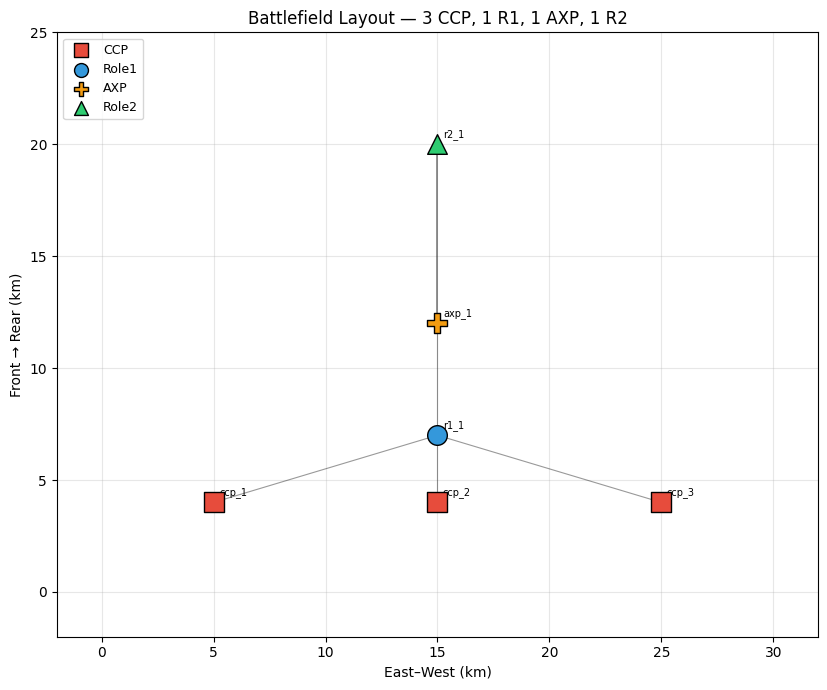

In [51]:
COLORS  = {"CCP": "#e74c3c", "Role1": "#3498db", "AXP": "#f39c12", "Role2": "#2ecc71"}
MARKERS = {"CCP": "s", "Role1": "o", "AXP": "P", "Role2": "^"}

fig, ax = plt.subplots(figsize=(14, 7))
fac_lookup = fac_df.set_index("facility_id")

# CCP → R1
for ccp_id, r1_id in ccp_r1_pairs:
    ccp, r1 = fac_lookup.loc[ccp_id], fac_lookup.loc[r1_id]
    ax.plot([ccp.x, r1.x], [ccp.y, r1.y], "k-", lw=0.8, alpha=0.4)

# R1 → AXP
for r1_id, axp_id in r1_to_axp.items():
    r1, axp = fac_lookup.loc[r1_id], fac_lookup.loc[axp_id]
    ax.plot([r1.x, axp.x], [r1.y, axp.y], "k-", lw=0.8, alpha=0.4)

# AXP → R2
for r2_id, axp_id in r2_to_axp.items():
    r2, axp = fac_lookup.loc[r2_id], fac_lookup.loc[axp_id]
    ax.plot([axp.x, r2.x], [axp.y, r2.y], "k-", lw=1.2, alpha=0.5)

for _, row in fac_df.iterrows():
    ft = row.facility_type
    ax.scatter(row.x, row.y, color=COLORS[ft], marker=MARKERS[ft],
               s=200, edgecolors="black", linewidths=1, zorder=5)
    ax.annotate(row.facility_id, (row.x, row.y),
                xytext=(4, 5), textcoords="offset points", fontsize=7)

handles = [plt.scatter([], [], color=COLORS[ft], marker=MARKERS[ft],
                        s=100, edgecolors="black", label=ft) for ft in COLORS]
ax.legend(handles=handles, loc="upper left", fontsize=9)
ax.set_xlim(-2, FRONTAGE_KM + 2)
ax.set_ylim(-2, Y_R2 + 5)
ax.set_xlabel("East–West (km)")
ax.set_ylabel("Front → Rear (km)")
ax.set_title(f"Battlefield Layout — {N_CCP} CCP, {N_R1} R1, {N_AXP} AXP, {N_R2} R2")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Cell 5 — Export distance matrix & coordinate reference

In [52]:
# Preview of distance matrix — all files are written in the final export cell
dist_df.round(2)

,ccp_1,ccp_2,ccp_3,r1_1,axp_1,r2_1
ccp_1,0.00,10.0,20.00,10.44,12.81,18.87
ccp_2,10.00,0.0,10.00,3.00,8.00,16.00
ccp_3,20.00,10.0,0.00,10.44,12.81,18.87
r1_1,10.44,3.0,10.44,0.00,5.00,13.00
axp_1,12.81,8.0,12.81,5.00,0.00,8.00
r2_1,18.87,16.0,18.87,13.00,8.00,0.00


## Cell 5b — Simulation facility table, AXPs, ambulances & C2

In [53]:
# ── Simulation facility table (CCPs, R1s, R2s — AXPs handled separately) ──────
def _c2_up(ft):
    if ft == "CCP":   return "C2_CCP_R1"
    if ft == "Role1": return "C2_R1_R2"
    return None   # Role2 has no upward C2 node

sim_fac_df = fac_df[fac_df["facility_type"] != "AXP"].copy().reset_index(drop=True)
sim_fac_df["c2_up_id"]      = sim_fac_df["facility_type"].map(_c2_up)
sim_fac_df["unload_policy"] = "unload_planned"
sim_fac_df["load_policy"]   = "load_planned"

sim_fac_ids  = sim_fac_df["facility_id"].tolist()
fac_type_map = dict(zip(sim_fac_df["facility_id"], sim_fac_df["facility_type"]))

# ── AXP table ─────────────────────────────────────────────────────────────────
axp_df = pd.DataFrame([
    {"axp_id": axp_id,
     "assigned_facility_ids": ",".join(axp_to_r1s.get(axp_id, []))}
    for axp_id in axp_xs
])

# ── Ambulance fleet ───────────────────────────────────────────────────────────
amb_rows, aid = [], 1
# CCP→R1 echelon: one group per R1, stationed at the R1
for r1_id in r1_xs:
    for _ in range(CCP_AMBS_PER_R1):
        amb_rows.append({"amb_id": f"AMB{aid:03d}", "c2_id": "C2_CCP_R1",
                         "start_loc_id": r1_id,
                         "t1_t2_capacity": AMB_CCP_R1_T1T2_CAPACITY, "t3_capacity": AMB_CCP_R1_T3_CAPACITY,
                         "speed_kmh": AMB_CCP_R1_SPEED_KMH})
        aid += 1
# R1→R2 echelon: one group per AXP, stationed at the AXP
for axp_id in axp_xs:
    for _ in range(R1R2_AMBS_PER_AXP):
        amb_rows.append({"amb_id": f"AMB{aid:03d}", "c2_id": "C2_R1_R2",
                         "start_loc_id": axp_id,
                         "t1_t2_capacity": AMB_R1_R2_T1T2_CAPACITY, "t3_capacity": AMB_R1_R2_T3_CAPACITY,
                         "speed_kmh": AMB_R1_R2_SPEED_KMH})
        aid += 1
amb_df = pd.DataFrame(amb_rows)

# ── C2 nodes ──────────────────────────────────────────────────────────────────
ccp_r1_amb_ids = ",".join(amb_df.loc[amb_df["c2_id"] == "C2_CCP_R1", "amb_id"])
r1_r2_amb_ids  = ",".join(amb_df.loc[amb_df["c2_id"] == "C2_R1_R2",  "amb_id"])

c2_df = pd.DataFrame([
    {"c2_id": "C2_CCP_R1",
     "facility_ids":  ",".join(ccp_xs.keys()),
     "ambulance_ids": ccp_r1_amb_ids},
    {"c2_id": "C2_R1_R2",
     "facility_ids":  ",".join(r1_xs.keys()),
     "ambulance_ids": r1_r2_amb_ids},
])

print(f"sim_fac_df:  {len(sim_fac_df)} rows  {sim_fac_df['facility_type'].value_counts().to_dict()}")
print(f"axp_df:      {len(axp_df)} AXPs")
print(f"amb_df:      {len(amb_df)} ambulances  "
      f"({N_R1 * CCP_AMBS_PER_R1} CCP→R1  +  {N_AXP * R1R2_AMBS_PER_AXP} R1→R2)")
print(f"c2_df:\n{c2_df[['c2_id','facility_ids']].to_string(index=False)}")

sim_fac_df:  5 rows  {'CCP': 3, 'Role1': 1, 'Role2': 1}
axp_df:      1 AXPs
amb_df:      5 ambulances  (1 CCP→R1  +  4 R1→R2)
c2_df:
    c2_id      facility_ids
C2_CCP_R1 ccp_1,ccp_2,ccp_3
 C2_R1_R2              r1_1


## Cell 6 — Build & export all simulation input files

Builds DataFrames for facilities, units, AXPs, ambulances, C2, and both
eligibility matrices, then writes them all to `OUT_BASE`.

In [54]:
# ── Units ──────────────────────────────────────────────────────────────────────
unit_rows, uid = [], 1
for _, row in sim_fac_df.iterrows():
    fid, ft = row["facility_id"], row["facility_type"]
    if ft == "Role1":
        for svc, cap, mn, mx in [("DCR", DCR_CAPACITY, DCR_MIN, DCR_MAX),
                                  ("PEC", PEC_CAPACITY, PEC_MIN, PEC_MAX)]:
            unit_rows.append({"unit_id": f"U{uid:03d}", "facility_id": fid,
                               "service_type": svc, "capacity": cap,
                               "service_time_min": mn, "service_time_max": mx})
            uid += 1
    elif ft == "Role2":
        for svc, cap, mn, mx in [("DCR", DCR_CAPACITY, DCR_MIN, DCR_MAX),
                                  ("PEC", PEC_CAPACITY, PEC_MIN, PEC_MAX)]:
            unit_rows.append({"unit_id": f"U{uid:03d}", "facility_id": fid,
                               "service_type": svc, "capacity": cap,
                               "service_time_min": mn, "service_time_max": mx})
            uid += 1
        unit_rows.append({"unit_id": f"U{uid:03d}", "facility_id": fid,
                           "service_type": "DCS", "capacity": DCS_CAPACITY,
                           "service_time_type": "normal_by_triage",
                           "service_time_mild_mean":    DCS_MILD_MEAN,
                           "service_time_mild_std":     DCS_MILD_STD,
                           "service_time_severe_mean":  DCS_SEVERE_MEAN,
                           "service_time_severe_std":   DCS_SEVERE_STD})
        uid += 1
units_df = pd.DataFrame(unit_rows)


In [55]:
# Reverse map: R1 → list of CCPs that feed it
r1_to_ccps = {}
for c, r in ccp_r1_pairs:
    r1_to_ccps.setdefault(r, []).append(c)

def make_fac_eligibility(loose=False):
    dm = pd.DataFrame(0, index=sim_fac_ids, columns=sim_fac_ids)
    for src in sim_fac_ids:
        if fac_type_map[src] == "CCP":
            for dst in sim_fac_ids:
                if fac_type_map[dst] != "Role1": continue
                dm.loc[src, dst] = 1 if (loose or ccp_to_r1.get(src) == dst) else 0
        elif fac_type_map[src] == "Role1":
            src_axp = r1_to_axp[src]
            for dst in sim_fac_ids:
                if fac_type_map[dst] != "Role2": continue
                dm.loc[src, dst] = 1 if (loose or r2_to_axp.get(dst) == src_axp) else 0
    return dm

def make_amb_eligibility(loose=False):
    dm = pd.DataFrame(0, index=amb_df["amb_id"].tolist(), columns=sim_fac_ids)
    for _, arow in amb_df.iterrows():
        aid, c2id, start = arow["amb_id"], arow["c2_id"], arow["start_loc_id"]
        if c2id == "C2_CCP_R1":
            if loose:
                for fid in sim_fac_ids:
                    if fac_type_map[fid] in ("CCP", "Role1"):
                        dm.loc[aid, fid] = 1
            else:
                # ambulance can visit its home R1 and all CCPs that feed that R1
                for fid in [start] + r1_to_ccps.get(start, []):
                    if fid in sim_fac_ids:
                        dm.loc[aid, fid] = 1
        elif c2id == "C2_R1_R2":
            axp_id  = start   # ambulance stationed at AXP
            axp_r1s = axp_to_r1s[axp_id]
            axp_r2s = [r2 for r2, a in r2_to_axp.items() if a == axp_id]
            for fid in sim_fac_ids:
                if loose:
                    if fac_type_map[fid] in ("Role1", "Role2"):
                        dm.loc[aid, fid] = 1
                else:
                    if fid in axp_r1s or fid in axp_r2s:
                        dm.loc[aid, fid] = 1
    return dm

fac_strict = make_fac_eligibility(loose=False)
fac_loose  = make_fac_eligibility(loose=True)
amb_strict = make_amb_eligibility(loose=False)
amb_loose  = make_amb_eligibility(loose=True)
print("Eligibility matrices built.")


Eligibility matrices built.


In [56]:
def _out(subpath):
    p = OUT_BASE / subpath
    p.parent.mkdir(parents=True, exist_ok=True)
    return p

# ── Facilities export — include real coordinates for visualization ─────────────
sim_fac_df["x_km"] = sim_fac_df["x"]
sim_fac_df["y_km"] = sim_fac_df["y"]

# ── Write all component files ──────────────────────────────────────────────────
exports = [
    (_out(f"components/distances/distance_matrix_{SUFFIX}.xlsx"),
     lambda p: dist_df.round(4).to_excel(p)),
    (_out(f"components/distances/coordinates_{SUFFIX}.xlsx"),
     lambda p: fac_df[["facility_id","facility_type","x","y"]].to_excel(p, index=False)),
    (_out(f"components/facilities/facilities_{SUFFIX}.xlsx"),
     lambda p: sim_fac_df[["facility_id","facility_type","c2_up_id",
                            "unload_policy","load_policy",
                            "x_km","y_km"]].to_excel(p, index=False)),
    (_out(f"components/units/units_{SUFFIX}.xlsx"),
     lambda p: units_df.to_excel(p, index=False)),
    (_out(f"components/AXPs/axp_{SUFFIX}.xlsx"),
     lambda p: axp_df.to_excel(p, index=False)),
    (_out(f"components/ambulances/amb_{SUFFIX}.xlsx"),
     lambda p: amb_df.to_excel(p, index=False)),
    (_out(f"components/c2/c2_{SUFFIX}.xlsx"),
     lambda p: c2_df.to_excel(p, index=False)),
    (_out(f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_strict.xlsx"),
     lambda p: fac_strict.to_excel(p)),
    (_out(f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_loose.xlsx"),
     lambda p: fac_loose.to_excel(p)),
    (_out(f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_strict.xlsx"),
     lambda p: amb_strict.to_excel(p)),
    (_out(f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_loose.xlsx"),
     lambda p: amb_loose.to_excel(p)),
]

for path, writer in exports:
    writer(path)
    print(f"  ✓ {path.relative_to(OUT_BASE)}")
print("Component files written.")

  ✓ components\distances\distance_matrix_elia_testing.xlsx
  ✓ components\distances\coordinates_elia_testing.xlsx
  ✓ components\facilities\facilities_elia_testing.xlsx
  ✓ components\units\units_elia_testing.xlsx
  ✓ components\AXPs\axp_elia_testing.xlsx
  ✓ components\ambulances\amb_elia_testing.xlsx
  ✓ components\c2\c2_elia_testing.xlsx
  ✓ policy_matrixes\facility_eligibility\facility_eligibility_elia_testing_strict.xlsx
  ✓ policy_matrixes\facility_eligibility\facility_eligibility_elia_testing_loose.xlsx
  ✓ policy_matrixes\ambulance_eligibility\ambulance_eligibility_elia_testing_strict.xlsx
  ✓ policy_matrixes\ambulance_eligibility\ambulance_eligibility_elia_testing_loose.xlsx
Component files written.


## Cell 7 — Casualty generation configuration

Verifies that the casualty config file referenced by `CASUALTY_CONFIG` exists.

All casualty parameters — PAR, `bcas_rate`, `dnbi_rate`, `n_days`, `waves_per_day`,
`wave_duration_min`, force structure, diagnosis mix, and prescriptions — are defined in:

```
casualty_generation_settings/sampling_settings/{CASUALTY_CONFIG}.yaml
```

The scenario YAML will contain only a `config` pointer to that file.  
To change any casualty parameter, edit the config YAML directly; do **not** hardcode values here.


In [57]:
# ── Verify casualty config exists ───────────────────────────────────────────
config_rel  = f"casualty_generation_settings/sampling_settings/{CASUALTY_CONFIG}.yaml"
config_path = OUT_BASE / config_rel

if config_path.exists():
    import yaml as _yaml
    with open(config_path, "r") as _f:
        _cfg = _yaml.safe_load(_f)
    print(f"  ✓ Casualty config found: {config_rel}")
    print(f"    n_days={_cfg.get('n_days')}  waves_per_day={_cfg.get('waves_per_day')}  "
          f"wave_duration_min={_cfg.get('wave_duration_min')}")
    print(f"    bcas_rate={_cfg.get('bcas_rate')}  dnbi_rate={_cfg.get('dnbi_rate')}")
    print(f"    force_structure: {_cfg.get('force_structure')}")
else:
    print(f"  ✗ Casualty config NOT found: {config_rel}")
    print(f"    Create it before running the simulation.")


  ✓ Casualty config found: casualty_generation_settings/sampling_settings/config_elia_testing.yaml
    n_days=1  waves_per_day=3  wave_duration_min=30
    bcas_rate=0.023  dnbi_rate=0
    force_structure: casualty_generation_settings/military_force_structure/force_structure_elia_testing.xlsx


In [59]:
scenario = {
    "name":        SCENARIO_NAME,
    "seed":        SEED,
    "description": SCENARIO_DESCRIPTION,
    "components": {
        "distance_matrix": f"components/distances/distance_matrix_{SUFFIX}.xlsx",
        "coordinates":     f"components/distances/coordinates_{SUFFIX}.xlsx",
        "axp":             f"components/AXPs/axp_{SUFFIX}.xlsx",
        "facilities":      f"components/facilities/facilities_{SUFFIX}.xlsx",
        "units":           f"components/units/units_{SUFFIX}.xlsx",
        "ambulances":      f"components/ambulances/amb_{SUFFIX}.xlsx",
        "c2":              f"components/c2/c2_{SUFFIX}.xlsx",
    },
    "policy_matrixes": {
        "facility_eligibility": {
            0: f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_strict.xlsx",
            1: f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_loose.xlsx",
        },
        "ambulance_eligibility": {
            0: f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_strict.xlsx",
            1: f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_loose.xlsx",
        },
    },
    "casualty_generation": {
        "config": f"casualty_generation_settings/sampling_settings/{CASUALTY_CONFIG}.yaml",
    },
    "levers": {
        "dispatch_policy":      DISPATCH_POLICY,
        "facility_eligibility":  0,
        "ambulance_eligibility": 0,
    },
    "simulation": {
        "till":                    SIM_TILL_MIN,
        "trace":                   False,
        "data_collector_interval": DATA_COLLECTOR_INTERVAL,
    },
    "video": {
        "enabled":            False,
        "fps":                24,
        "time_scale":         5.0,
        "dpi":                100,
        "state_log_interval": 5.0,
        "start_time":         0,
        "duration":           None,
    },
    "logs":    {"enabled": True, "path": "simulation_logs"},
    "outputs": {
        "patient_log":       True,
        "safe_patients":     True,
        "transport_events":  True,
        "wait_times":        True,
        "facility_states":   False,
    },
}

scenario_path = _out(f"scenarios/{SCENARIO_NAME}.yaml")
with open(scenario_path, "w", encoding="utf-8") as f:
    yaml.dump(scenario, f, default_flow_style=False, allow_unicode=True, sort_keys=False)
print(f"  ✓ {scenario_path.relative_to(OUT_BASE)}")


  ✓ scenarios\scenario_elia_testing.yaml
